# Trabalhando com imagens de marte feitas pelo Curiosity a fins de aprendizado do OpenCV, Numpy e Matplot
## 1 - Entendendo a Matriz:
Função para mudar a imagem para RGB e retonar suas dimenções:

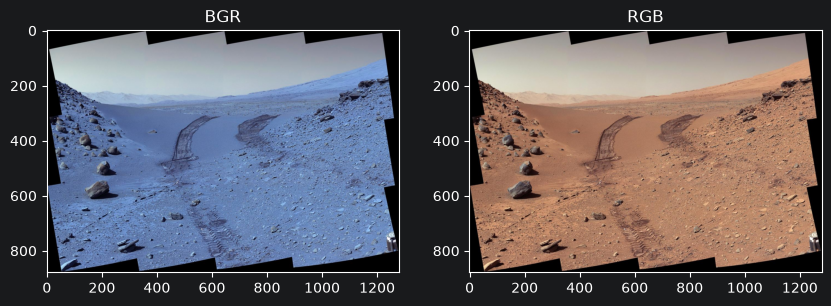

In [1]:
import cv2
from IPython.core.pylabtools import figsize
from matplotlib import pyplot as plt

def load_dim_image(imagePath):
    image_BGR = cv2.imread(imagePath)
    image_RGB = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2RGB)
    height, width, _= image_BGR.shape
    return image_BGR,image_RGB, height, width

image_BGR, image_RGB, heigth, width = load_dim_image("data/curiosity/colorida/cor_09_curiosity_archive_sol0_SCIENCE.png")

fig, axes = plt.subplots(1, 2, figsize=(10,5))
axes[0].imshow(image_BGR)
axes[0].set_title('BGR')

axes[1].imshow(image_RGB)
axes[1].set_title('RGB')
plt.show()

Retornando a imagem cortada e o numero de píxeis na linha 5.

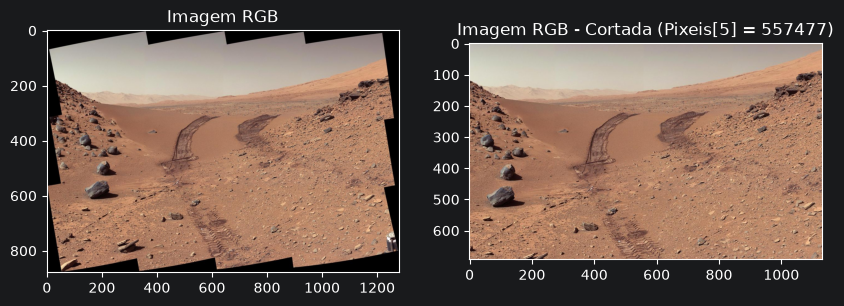

In [20]:
import numpy as np

def cut_image(image_RGB):
    # Cotando a imagem
    cut_image_RGB = image_RGB[87:780, 83:1213]

    # Soma a quantidade de píxeis na linha 5
    sum_pixel = int(np.sum(cut_image_RGB[5, :]))

    return cut_image_RGB, sum_pixel

cut_image_RGB, sum_pixel = cut_image(image_RGB)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].set_title("Imagem RGB")
axes[0].imshow(image_RGB)

axes[1].set_title(f"Imagem RGB - Cortada (Pixeis[5] = {sum_pixel})")
axes[1].imshow(cut_image_RGB)

plt.imsave("data/curiosity/colorida/imgRGB-ex.png", cut_image_RGB)

Quantizando a imagem

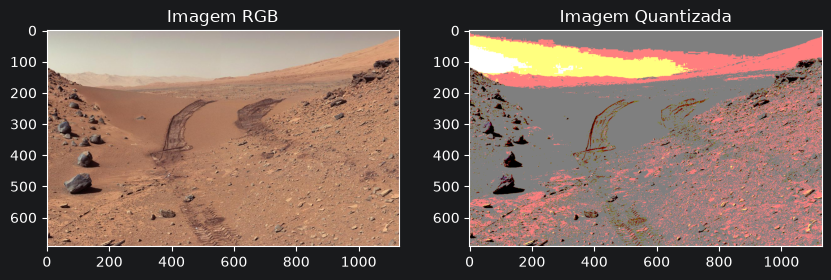

In [42]:
def quantization_image(image):
    image_f = image.astype(np.float32)
    level = 3
    image_quant = np.round((image_f * (level - 1) / 255.0))
    image_quant_int = image_quant.astype(np.int32)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].set_title('Imagem RGB')
    axes[0].imshow(image)

    axes[1].set_title('Imagem Quantizada')
    axes[1].imshow(image_quant_int / (level - 1))

    plt.show()

    return image_quant

image_quant = quantization_image(cut_image_RGB)


Descobrindo quantas cores RGB diferentes existem em uma imagem quantizada de Marte

In [6]:
def different_colors(image):
    print(f"Imagem - 3Dimensões: {np.shape(image)}")
    # transformando numa grade 2D
    image_2D = image.reshape(-1, 3)
    print(f"Imagem - 2Dimensões: {np.shape(image_2D)}")
    unique_colors = np.unique(image_2D, axis=0)
    print(f"Quantidade de cores únicas: {len(unique_colors)}")
    return unique_colors

different_colors(image_quant)

Imagem - 3Dimensões: (693, 1130, 3)
Imagem - 2Dimensões: (783090, 3)
Quantidade de cores únicas: 10


array([[0., 0., 0.],
       [0., 0., 1.],
       [0., 1., 1.],
       [1., 0., 0.],
       [1., 0., 1.],
       [1., 1., 0.],
       [1., 1., 1.],
       [2., 1., 1.],
       [2., 2., 1.],
       [2., 2., 2.]], dtype=float32)

Função para ampliar uma imagem x vezes sem inventar cores

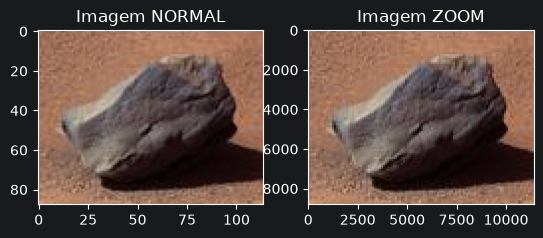

In [52]:
def zoom_pure_image(image, x, y):
    image_zoom = cv2.resize(image, None, fx=x, fy=y, interpolation=cv2.INTER_NEAREST)

    fig, axes = plt.subplots(1, 2)
    axes[0].imshow(image)
    axes[0].set_title("Imagem NORMAL")
    axes[1].imshow(image_zoom)
    axes[1].set_title("Imagem ZOOM")
    plt.show()


pedra = cut_image_RGB[445:533,44:158]
zoom_pure_image(pedra, 100, 100)

plt.imsave("data/curiosity/colorida/pedra.png", pedra)

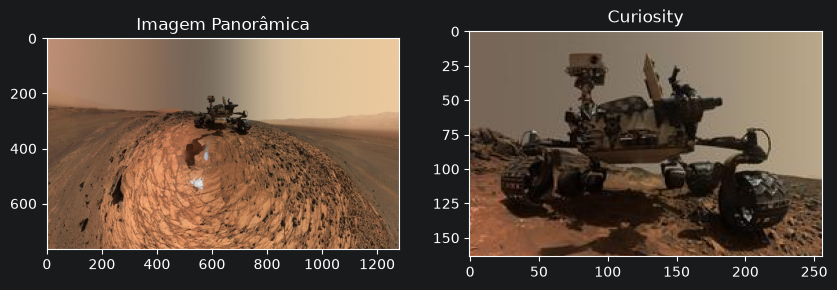

In [48]:
panorama_curiosity = cv2.imread("data/curiosity/colorida/cor_10_curiosity_archive_sol0_SCIENCE.png")
panorama_curiosity_RGB = cv2.cvtColor(panorama_curiosity, cv2.COLOR_BGR2RGB)

curiosity = panorama_curiosity_RGB[192:356,512:768]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].set_title("Imagem Panorâmica")
axes[0].imshow(panorama_curiosity_RGB)
axes[1].set_title("Curiosity")
axes[1].imshow(curiosity)
plt.show()